# Lab 06 — Decision Trees and Ensemble Learning
## Notebook 01 — In-class Demonstration

**Dataset:** Breast Cancer Wisconsin dataset from `scikit-learn`.

The notebook begins with one Decision Tree and then extends the same classification task to **Bagging, Random Forest, AdaBoost, and Voting** so that their results can be compared on the same train/test split.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    VotingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay,
    classification_report
)

RANDOM_STATE = 42

## 2. Load and inspect the dataset

Decision Trees generally do not require standardization because they split using feature thresholds. Later, Logistic Regression and KNN are placed inside scaling pipelines for the VotingClassifier.

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data.copy()
y = data.target.copy()

print("X shape:", X.shape)
print("Target names:", list(data.target_names))
print("Number of features:", X.shape[1])
display(X.head())

class_counts = y.value_counts().sort_index()
display(pd.DataFrame({
    "class_id": class_counts.index,
    "class_name": [data.target_names[i] for i in class_counts.index],
    "count": class_counts.values
}))

X shape: (569, 30)
Target names: [np.str_('malignant'), np.str_('benign')]
Number of features: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,class_id,class_name,count
0,0,malignant,212
1,1,benign,357


## 3. Create one train/test split for all models

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 455
Test samples: 114


# 4. Gini impurity

Gini impurity measures how mixed the classes are inside a node:

\[
Gini = 1 - \sum_i p_i^2
\]

Lower Gini means a purer node.

In [4]:
def gini_from_counts(counts):
    counts = np.asarray(counts, dtype=float)
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)

examples = {
    "10 Yes, 0 No": [10, 0],
    "8 Yes, 2 No": [8, 2],
    "5 Yes, 5 No": [5, 5]
}

for name, counts in examples.items():
    print(f"{name:15s} -> Gini = {gini_from_counts(counts):.3f}")

10 Yes, 0 No    -> Gini = 0.000
8 Yes, 2 No     -> Gini = 0.320
5 Yes, 5 No     -> Gini = 0.500


### Quick Question 1

**What does Gini = 0 mean for a Decision Tree node?**

**Answer:**  
...

## 4.1 Weighted Gini and impurity reduction

In [5]:
parent = [6, 4]
left_1 = [4, 0]
right_1 = [2, 4]

g_parent = gini_from_counts(parent)
weighted_1 = (
    (sum(left_1) / sum(parent)) * gini_from_counts(left_1)
    + (sum(right_1) / sum(parent)) * gini_from_counts(right_1)
)
reduction_1 = g_parent - weighted_1

left_2 = [3, 2]
right_2 = [3, 2]
weighted_2 = (
    (sum(left_2) / sum(parent)) * gini_from_counts(left_2)
    + (sum(right_2) / sum(parent)) * gini_from_counts(right_2)
)
reduction_2 = g_parent - weighted_2

display(pd.DataFrame({
    "Candidate split": ["Split 1", "Split 2"],
    "Weighted child Gini": [weighted_1, weighted_2],
    "Gini reduction": [reduction_1, reduction_2]
}))

,Candidate split,Weighted child Gini,Gini reduction
0,Split 1,0.266667,0.213333
1,Split 2,0.480000,0.000000


The tree selects a candidate split that gives a strong impurity reduction, then recursively repeats the same process inside the resulting child nodes.

# 5. Train an unrestricted Decision Tree

In [6]:
tree_unrestricted = DecisionTreeClassifier(
    criterion="gini",
    random_state=RANDOM_STATE
)
tree_unrestricted.fit(X_train, y_train)

tree_train_pred = tree_unrestricted.predict(X_train)
tree_test_pred = tree_unrestricted.predict(X_test)

train_acc_tree = accuracy_score(y_train, tree_train_pred)
test_acc_tree = accuracy_score(y_test, tree_test_pred)

print(f"Training accuracy: {train_acc_tree:.4f}")
print(f"Test accuracy:     {test_acc_tree:.4f}")
print("Tree depth:", tree_unrestricted.get_depth())
print("Leaves:", tree_unrestricted.get_n_leaves())

Training accuracy: 1.0000
Test accuracy:     0.9123
Tree depth: 7
Leaves: 19


### Quick Question 2

**If training accuracy is extremely high but test accuracy is lower, what problem might this indicate?**

**Answer:**  
...

# 6. Visualize and interpret the learned tree

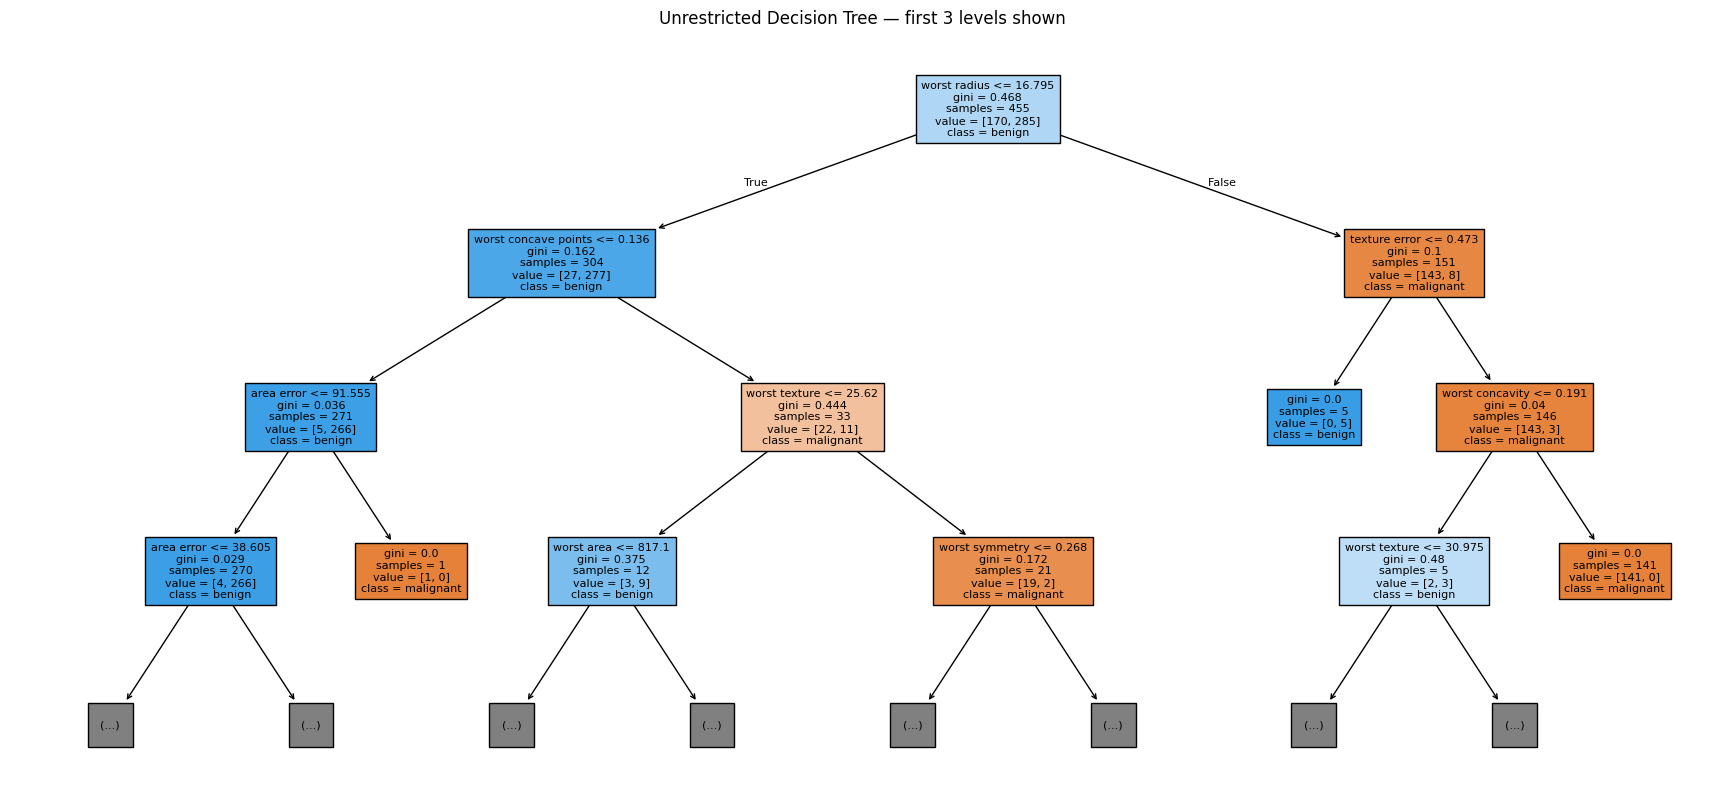

In [7]:
plt.figure(figsize=(22, 10))
plot_tree(
    tree_unrestricted,
    feature_names=X.columns,
    class_names=list(data.target_names),
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title("Unrestricted Decision Tree — first 3 levels shown")
plt.show()

In [8]:
root_feature_index = tree_unrestricted.tree_.feature[0]
root_threshold = tree_unrestricted.tree_.threshold[0]
root_feature = X.columns[root_feature_index]

print("Root feature:", root_feature)
print("Root threshold:", root_threshold)
print(f"Root question: Is {root_feature} <= {root_threshold:.4f}?")

Root feature: worst radius
Root threshold: 16.795000076293945
Root question: Is worst radius <= 16.7950?


In [9]:
print(export_text(
    tree_unrestricted,
    feature_names=list(X.columns),
    max_depth=4
))

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 91.56
|   |   |   |--- area error <= 38.60
|   |   |   |   |--- smoothness error <= 0.00
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- smoothness error >  0.00
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- area error >  38.60
|   |   |   |   |--- texture error <= 2.01
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- texture error >  2.01
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |--- area error >  91.56
|   |   |   |--- class: 0
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 25.62
|   |   |   |--- worst area <= 817.10
|   |   |   |   |--- worst smoothness <= 0.18
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- worst smoothness >  0.18
|   |   |   |   |   |--- class: 0
|   |   |   |--- worst area >  817.10
|   |   |   |   |--- class: 0
|   |   |--- worst texture >  25.62
|   |   |   |--- worst

# 7. Evaluate the baseline tree

              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



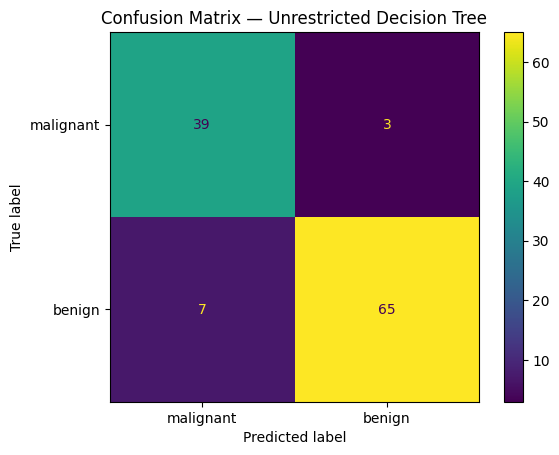

In [10]:
print(classification_report(
    y_test,
    tree_test_pred,
    target_names=data.target_names
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    tree_test_pred,
    display_labels=data.target_names
)
plt.title("Confusion Matrix — Unrestricted Decision Tree")
plt.show()

# 8. Control tree complexity

In [11]:
tree_controlled = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_leaf=5,
    random_state=RANDOM_STATE
)
tree_controlled.fit(X_train, y_train)

controlled_train_pred = tree_controlled.predict(X_train)
controlled_test_pred = tree_controlled.predict(X_test)

train_acc_controlled = accuracy_score(y_train, controlled_train_pred)
test_acc_controlled = accuracy_score(y_test, controlled_test_pred)

display(pd.DataFrame({
    "Model": ["Unrestricted tree", "Controlled tree"],
    "Training accuracy": [train_acc_tree, train_acc_controlled],
    "Test accuracy": [test_acc_tree, test_acc_controlled],
    "Depth": [tree_unrestricted.get_depth(), tree_controlled.get_depth()],
    "Leaves": [tree_unrestricted.get_n_leaves(), tree_controlled.get_n_leaves()]
}))

,Model,Training accuracy,Test accuracy,Depth,Leaves
0,Unrestricted tree,1.000000,0.912281,7,19
1,Controlled tree,0.975824,0.921053,4,10


## 8.1 Explore max_depth

,max_depth,train_accuracy,test_accuracy,leaves
0,1,0.923077,0.921053,2
1,2,0.958242,0.894737,4
2,3,0.975824,0.938596,7
3,4,0.986813,0.938596,11
4,5,0.993407,0.921053,15
5,6,0.997802,0.912281,18
6,7,1.000000,0.912281,19
7,8,1.000000,0.912281,19
8,9,1.000000,0.912281,19
9,10,1.000000,0.912281,19


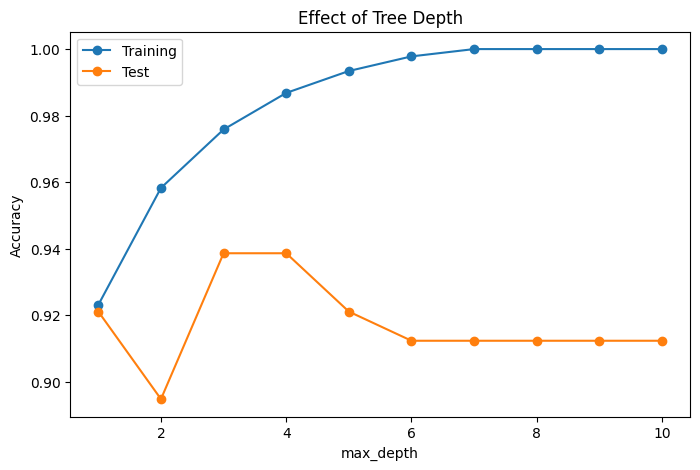

In [12]:
depth_results = []

for depth in range(1, 11):
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=RANDOM_STATE
    )
    model.fit(X_train, y_train)
    depth_results.append({
        "max_depth": depth,
        "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, model.predict(X_test)),
        "leaves": model.get_n_leaves()
    })

depth_results = pd.DataFrame(depth_results)
display(depth_results)

plt.figure(figsize=(8, 5))
plt.plot(depth_results["max_depth"], depth_results["train_accuracy"], marker="o", label="Training")
plt.plot(depth_results["max_depth"], depth_results["test_accuracy"], marker="o", label="Test")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth")
plt.legend()
plt.show()

# 9. Gini vs Entropy

In [13]:
tree_gini = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=RANDOM_STATE
)
tree_entropy = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    random_state=RANDOM_STATE
)

tree_gini.fit(X_train, y_train)
tree_entropy.fit(X_train, y_train)

display(pd.DataFrame({
    "Criterion": ["Gini", "Entropy"],
    "Training accuracy": [
        accuracy_score(y_train, tree_gini.predict(X_train)),
        accuracy_score(y_train, tree_entropy.predict(X_train))
    ],
    "Test accuracy": [
        accuracy_score(y_test, tree_gini.predict(X_test)),
        accuracy_score(y_test, tree_entropy.predict(X_test))
    ],
    "Depth": [tree_gini.get_depth(), tree_entropy.get_depth()],
    "Leaves": [tree_gini.get_n_leaves(), tree_entropy.get_n_leaves()]
}))

,Criterion,Training accuracy,Test accuracy,Depth,Leaves
0,Gini,0.986813,0.938596,4,11
1,Entropy,0.984615,0.938596,4,11


# 10. Feature importance

,feature,importance
20,worst radius,0.751145
27,worst concave points,0.124955
11,texture error,0.046883
21,worst texture,0.033095
26,worst concavity,0.017573
24,worst smoothness,0.010614
13,area error,0.007497
6,mean concavity,0.006162
23,worst area,0.002077
0,mean radius,0.000000


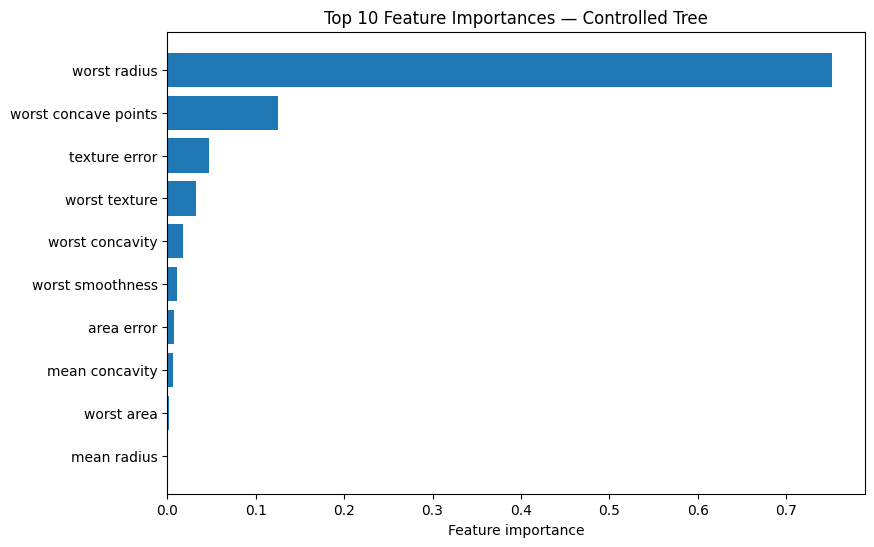

In [14]:
importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": tree_controlled.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df.head(10))

top = importance_df.head(10).sort_values("importance")
plt.figure(figsize=(9, 6))
plt.barh(top["feature"], top["importance"])
plt.xlabel("Feature importance")
plt.title("Top 10 Feature Importances — Controlled Tree")
plt.show()

# 11. Ensemble methods: practical construction

We now keep the same classification problem and compare several ways of combining models.

## 11.1 BaggingClassifier

A Decision Tree is used as the **base learner**. Bagging trains many versions independently using bootstrap samples and combines their predictions.

In [15]:
base_tree = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

bagging_model = BaggingClassifier(
    estimator=base_tree,
    n_estimators=100,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)

bagging_train_pred = bagging_model.predict(X_train)
bagging_test_pred = bagging_model.predict(X_test)

train_acc_bagging = accuracy_score(y_train, bagging_train_pred)
test_acc_bagging = accuracy_score(y_test, bagging_test_pred)

print(f"Bagging training accuracy: {train_acc_bagging:.4f}")
print(f"Bagging test accuracy:     {test_acc_bagging:.4f}")

Bagging training accuracy: 1.0000
Bagging test accuracy:     0.9386


### Quick Question 3

**What is the base learner here, and are the base learners trained independently or sequentially?**

**Answer:**  
...

## 11.2 Random Forest

Random Forest is a bagging-based ensemble of Decision Trees that additionally introduces random feature selection during split search.

In [16]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

train_acc_rf = accuracy_score(y_train, rf_train_pred)
test_acc_rf = accuracy_score(y_test, rf_test_pred)

print(f"Random Forest training accuracy: {train_acc_rf:.4f}")
print(f"Random Forest test accuracy:     {test_acc_rf:.4f}")

Random Forest training accuracy: 1.0000
Random Forest test accuracy:     0.9561


### Quick Question 4

**What additional source of randomness does Random Forest introduce compared with ordinary bagging of Decision Trees?**

**Answer:**  
...

## 11.3 AdaBoostClassifier

AdaBoost trains its base learners **sequentially**. Here the base learner is a shallow Decision Tree (a decision stump).

In [17]:
weak_tree = DecisionTreeClassifier(
    max_depth=1,
    random_state=RANDOM_STATE
)

adaboost_model = AdaBoostClassifier(
    estimator=weak_tree,
    n_estimators=100,
    learning_rate=0.5,
    random_state=RANDOM_STATE
)

adaboost_model.fit(X_train, y_train)

adaboost_train_pred = adaboost_model.predict(X_train)
adaboost_test_pred = adaboost_model.predict(X_test)

train_acc_adaboost = accuracy_score(y_train, adaboost_train_pred)
test_acc_adaboost = accuracy_score(y_test, adaboost_test_pred)

print(f"AdaBoost training accuracy: {train_acc_adaboost:.4f}")
print(f"AdaBoost test accuracy:     {test_acc_adaboost:.4f}")

AdaBoost training accuracy: 1.0000
AdaBoost test accuracy:     0.9561


### Quick Question 5

**Why is AdaBoost classified as boosting rather than bagging?**

**Answer:**  
...

## 11.4 VotingClassifier

Voting combines **different independently trained classifiers**. With hard voting, the final class is selected from the component classifiers' class predictions.

In [18]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

voting_tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=RANDOM_STATE
)

voting_model = VotingClassifier(
    estimators=[
        ("logistic", logistic_model),
        ("knn", knn_model),
        ("tree", voting_tree)
    ],
    voting="hard"
)

voting_model.fit(X_train, y_train)

voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)

train_acc_voting = accuracy_score(y_train, voting_train_pred)
test_acc_voting = accuracy_score(y_test, voting_test_pred)

print(f"Voting training accuracy: {train_acc_voting:.4f}")
print(f"Voting test accuracy:     {test_acc_voting:.4f}")

Voting training accuracy: 0.9868
Voting test accuracy:     0.9825


/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features

### Quick Question 6

**How is VotingClassifier different from BaggingClassifier when choosing its component models?**

**Answer:**  
...

# 12. Final comparison of all models

In [19]:
final_results = pd.DataFrame({
    "Model": [
        "Decision Tree — unrestricted",
        "Decision Tree — controlled",
        "Bagging",
        "Random Forest",
        "AdaBoost",
        "Voting Classifier"
    ],
    "Training Accuracy": [
        train_acc_tree,
        train_acc_controlled,
        train_acc_bagging,
        train_acc_rf,
        train_acc_adaboost,
        train_acc_voting
    ],
    "Test Accuracy": [
        test_acc_tree,
        test_acc_controlled,
        test_acc_bagging,
        test_acc_rf,
        test_acc_adaboost,
        test_acc_voting
    ]
})

display(final_results.sort_values("Test Accuracy", ascending=False))

,Model,Training Accuracy,Test Accuracy
5,Voting Classifier,0.986813,0.982456
3,Random Forest,1.000000,0.956140
4,AdaBoost,1.000000,0.956140
2,Bagging,1.000000,0.938596
1,Decision Tree — controlled,0.975824,0.921053
0,Decision Tree — unrestricted,1.000000,0.912281


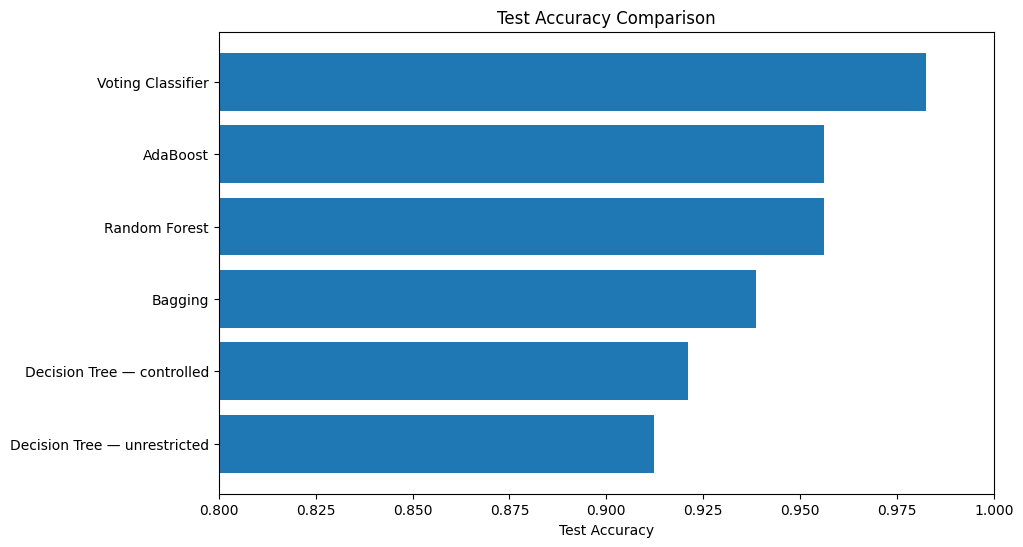

In [20]:
plot_results = final_results.sort_values("Test Accuracy")

plt.figure(figsize=(10, 6))
plt.barh(plot_results["Model"], plot_results["Test Accuracy"])
plt.xlabel("Test Accuracy")
plt.title("Test Accuracy Comparison")
plt.xlim(0.80, 1.00)
plt.show()

### Quick Question 7

**Did every ensemble outperform the single Decision Tree? What does the comparison tell you about evaluating models experimentally?**

**Answer:**  
...

## 13. Main takeaways

- A single Decision Tree learns a hierarchy of split rules.
- Gini impurity helps select splits that create purer child nodes.
- Tree complexity should be checked because unrestricted trees can overfit.
- Bagging trains many versions of a base learner independently using bootstrap samples.
- Random Forest is a bagging-based tree ensemble with random feature selection.
- AdaBoost trains base learners sequentially.
- VotingClassifier combines predictions from different independently trained classifiers.
- Ensemble methods are not guaranteed to outperform every single model; performance must be evaluated on unseen data.